# Primera Red Neuronal Profunda
En este notebook se aplicara todo lo visto durante el primer parcial de Aprendizaje Profundo. <br>
**Problema:**  Las calificaciones crediticias corporativas, emitidas por agencias como Standard & Poor's y Moody's, expresan la opinión de la agencia sobre la capacidad de una empresa para cumplir con sus obligaciones de deuda. Cada agencia aplica su propia metodología para medir la solvencia, y esta evaluación es un proceso costoso y complejo. Por lo general, las agencias tardan en proporcionar nuevas calificaciones y actualizar las anteriores. Esto provoca demoras en el proceso de toma de decisiones para los inversores que utilizan estas calificaciones para evaluar su riesgo crediticio.

### Aprendizaje sensible al costo.
Un error en una clase rara cuesta más que uno en una clase común
$L = \sum_i w_{y_i}\cdot CE_i$

## Metricas realizadas con otros métodos
Estas metricas fueron realizadas con métodos de aprendizaje no supervisado y con frameworks de Machine Learning 
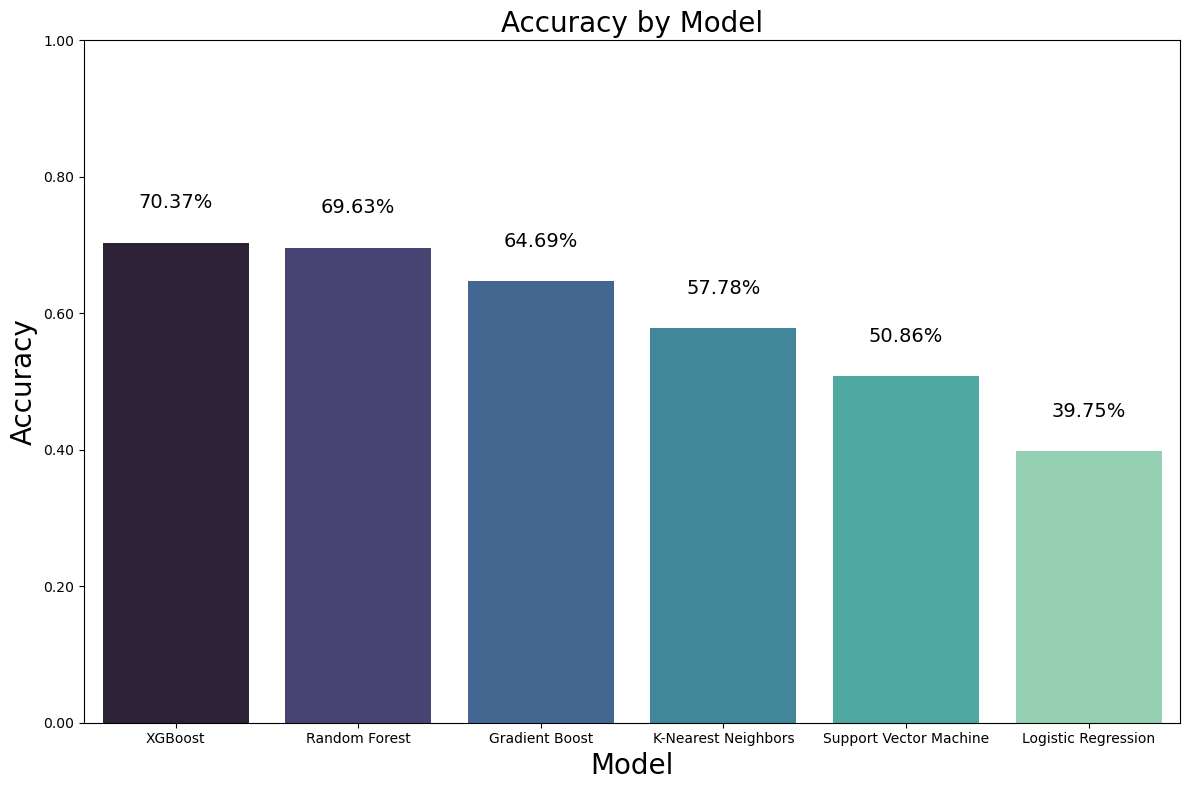

## Resumen 


In [107]:
import json, os
import pandas as pd

RUTA = 'resumen_ejecutivo.json'
if os.path.exists(RUTA):
    with open(RUTA, encoding='utf-8') as f:
        r = json.load(f)
    display(pd.DataFrame(r['tabla']).set_index('Modelo'))
    print(f"Escalador: {r['escalador']} | Semilla: {r['semilla']}")
    print(f"Configuración MLP final: {r['config_mlp']}")

,Accuracy,Macro-F1,±1 clase,CE
Modelo,,,,
Clase mayoritaria,0.1977,0.0367,0.4392,2.1102
Random Forest,0.4259,0.3979,0.8118,1.8432
HistGradientBoosting,0.4202,0.3927,0.7966,1.7789
MLP final (este notebook),0.3840,0.3817,0.6844,1.6001


Escalador: robust_clip | Semilla: 1969
Configuración MLP final: {'l1': 0.0, 'capas': [64, 64], 'activacion': 'elu', 'optimizador': 'adam', 'learning_rate': 0.0017, 'batchnorm': True, 'pesos': 'suave', 'dropout': 0.05, 'l2': 1e-05}


## Liberias y dataset

In [53]:
# Librerias  
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
# Preprocesamiento
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
# TensorFlow
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers, callbacks
import os, random, json
from sklearn.preprocessing import RobustScaler, QuantileTransformer, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import f1_score, confusion_matrix, log_loss
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

In [54]:
SEED = 1969
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()   # operaciones deterministas
except Exception as e:
    print("Determinismo de operaciones no disponible:", e)
print(f"Semilla fijada: {SEED}")

Semilla fijada: 1969


### Importación del dataset y target

In [55]:
# Carga del conjunto de datos con datos explicitos
df = pd.read_csv('Data/CorporateCredit.csv',
dtype={
        'Rating Agency': 'category',
        'Rating': 'category',
        'Binary Rating': 'boolean',
        'SIC Code': 'string',
        'Sector': 'category',
        'Ticker': 'string'
    }
)
target = 'Rating'

In [56]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7805 entries, 0 to 7804
Data columns (total 25 columns):
 #   Column                         Non-Null Count  Dtype   
---  ------                         --------------  -----   
 0   Rating Agency                  7805 non-null   category
 1   Corporation                    7805 non-null   str     
 2   Rating                         7805 non-null   category
 3   Rating Date                    7805 non-null   str     
 4   CIK                            7805 non-null   int64   
 5   Binary Rating                  7805 non-null   boolean 
 6   SIC Code                       7805 non-null   string  
 7   Sector                         7805 non-null   category
 8   Ticker                         7805 non-null   string  
 9   Current Ratio                  7805 non-null   float64 
 10  Long-term Debt / Capital       7805 non-null   float64 
 11  Debt/Equity Ratio              7805 non-null   float64 
 12  Gross Margin                   7805 non-null 

| Columna | Descripción |
| :--- | :--- |
| **Rating Agency** | Clasificadora de riesgo que asigna la nota (ej. S&P, Moody's, Fitch). |
| **Corporation** | Nombre de la empresa o corporación evaluada. |
| **Rating** | Calificación crediticia asignada que indica el nivel de riesgo. |
| **Rating Date** | Fecha de emisión o actualización de la calificación crediticia. |
| **CIK** | Número único asignado por la SEC para identificar a la empresa en EE. UU. |
| **Binary Rating** | Indicador binario (Verdadero/Falso) que simplifica el nivel de riesgo (ej. Grado de Inversión vs. Basura). |
| **SIC Code** | Código estándar de clasificación industrial de la actividad principal de la empresa. |
| **Sector** | Sector económico en el que opera la empresa. |
| **Ticker** | Símbolo de cotización bursátil de las acciones (ej. AAPL, MSFT). |
| **Current Ratio** | Mide la capacidad de pagar deudas a corto plazo con activos a corto plazo. |
| **Long-term Debt / Capital** | Proporción del capital total financiado con deuda a largo plazo. |
| **Debt/Equity Ratio** | Relación entre la deuda total y el patrimonio neto de los accionistas. |
| **Gross Margin** | Porcentaje de ingresos que queda tras restar los costos directos de producción. |
| **Operating Margin** | Porcentaje de ingresos restante tras descontar los gastos operativos. |
| **EBIT Margin** | Margen de beneficio antes de intereses e impuestos respecto a los ingresos. |
| **EBITDA Margin** | Margen operativo excluyendo también depreciaciones y amortizaciones. |
| **Pre-Tax Profit Margin** | Porcentaje de ganancia obtenido antes de pagar impuestos corporativos. |
| **Net Profit Margin** | Porcentaje final de ingresos que se convierte en ganancia neta. |
| **Asset Turnover** | Eficiencia con la que la empresa usa sus activos para generar ventas. |
| **ROE - Return On Equity** | Rentabilidad generada sobre el patrimonio de los accionistas. |
| **Return On Tangible Equity** | Retorno generado sobre el patrimonio tangible (excluyendo intangibles como patentes). |
| **ROA - Return On Assets** | Rentabilidad generada con respecto al total de activos. |
| **ROI - Return On Investment** | Mide la eficiencia económica global del capital invertido. |
| **Operating Cash Flow Per Share** | Efectivo generado por operaciones por cada acción en circulación. |
| **Free Cash Flow Per Share** | Flujo de caja libre disponible por cada acción en circulación. |

C:\Users\kevin\AppData\Local\Temp\ipykernel_7464\1897345634.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


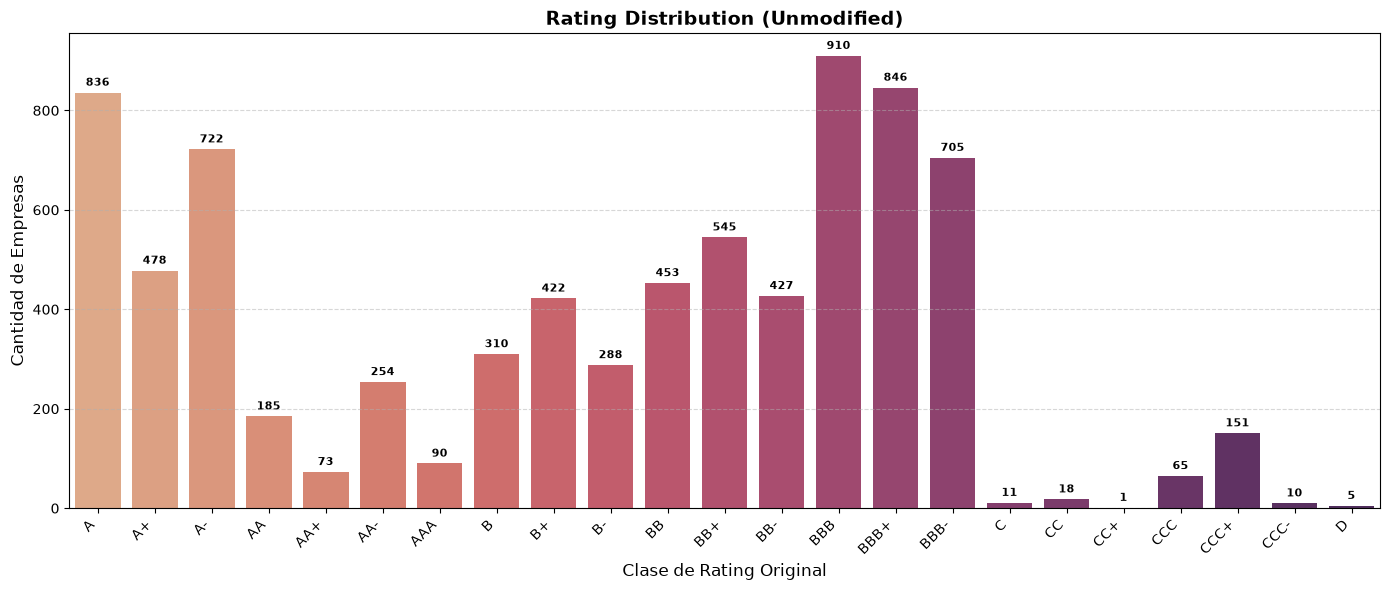

In [57]:
# 2. Configuración de lienzo ampliado para albergar 23 columnas
fig, ax = plt.subplots(figsize=(14, 6))

# 3. Gráfico de distribución original
sns.countplot(
    data=df, 
    x=target,  
    palette="flare", 
    ax=ax
)

# 4. Formato y etiquetas
ax.set_title("Rating Distribution (Unmodified)", fontsize=14, fontweight='bold')
ax.set_xlabel("Clase de Rating Original", fontsize=12)
ax.set_ylabel("Cantidad de Empresas", fontsize=12)

# Rotación de etiquetas a 45 grados y cuadrícula vertical de soporte
plt.xticks(rotation=45, ha='right')
ax.grid(axis='y', linestyle='--', alpha=0.5)

# 5. Anotación numérica sobre cada barra (manejando clases con 0 registros)
for p in ax.patches:
    height = p.get_height()
    if not np.isnan(height) and height > 0:
        ax.annotate(
            f'{int(height)}', 
            (p.get_x() + p.get_width() / 2., height),
            ha='center', va='bottom', 
            xytext=(0, 3), textcoords='offset points',
            fontsize=8, fontweight='bold'
        )

plt.tight_layout()
plt.show()

## Preprocesamiento de los datos

In [58]:
FUSIONAR_DEFAULT = True   # True -> 9 clases (D dentro de la última) | False -> 10 clases (D separada)

# ---------------------------------------------------------------
# 0) Respaldo del rating original (la primera vez) para poder
#    re-ejecutar la celda sin romper nada
# ---------------------------------------------------------------
if 'rating_original' not in df.columns:
    df['rating_original'] = df[target].astype(str)

columnas_descarte = ['CIK', 'Corporation', 'Binary Rating', 'Rating Date', 'Ticker', 'SIC Code']
df = df.drop(columns=columnas_descarte, errors='ignore')

n_antes = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicados eliminados: {n_antes - len(df)} (quedan {len(df)} filas)")

Duplicados eliminados: 2551 (quedan 5254 filas)


### Mapa de calor variables

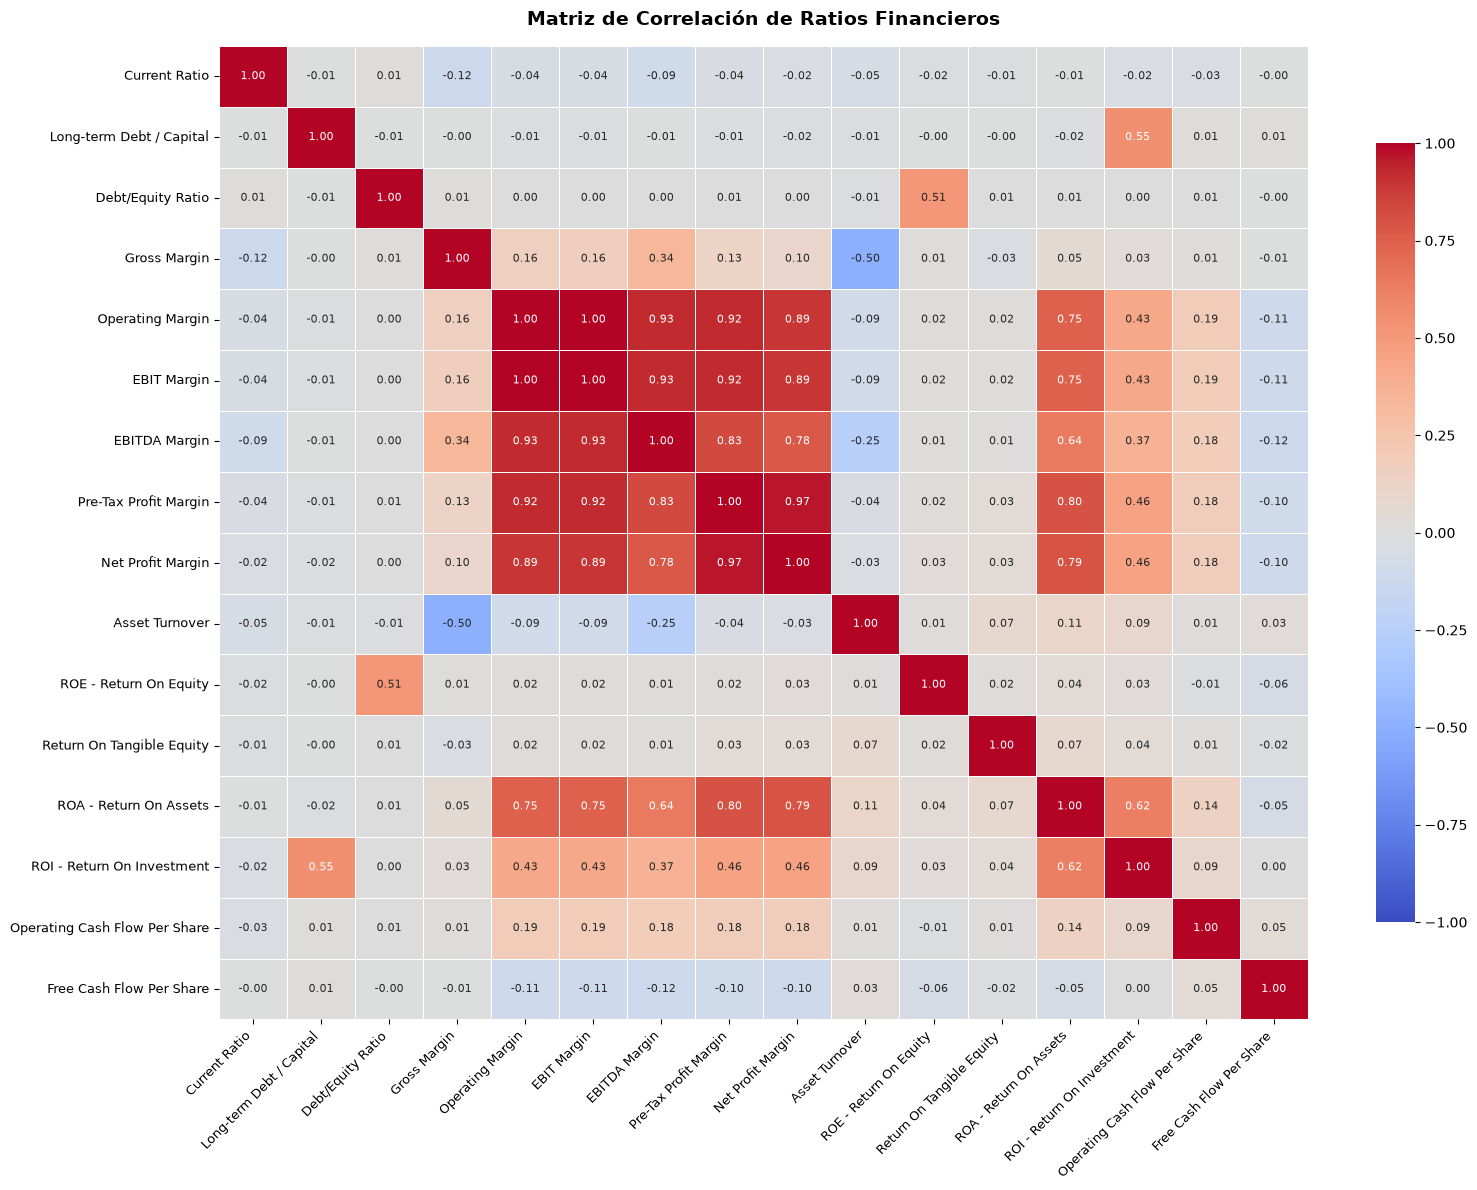

In [59]:
# 1. Ajuste de dimensiones del lienzo para albergar las ~16 variables numéricas
fig, ax = plt.subplots(figsize=(16, 12))

# 2. Matriz de correlación restringida a tipos numéricos
corr_matrix = df.select_dtypes(include='number').corr()

# 3. Mapa de calor con escala divergente y tamaño de fuente ajustado por celda
sns.heatmap(
    corr_matrix, 
    ax=ax, 
    annot=True, 
    fmt='.2f', 
    cmap='coolwarm', 
    vmin=-1, 
    vmax=1, 
    linewidths=0.5,
    annot_kws={"size": 8},
    cbar_kws={"shrink": 0.8}
)

# 4. Alineación y rotación de nombres de columnas para evitar superposición
ax.set_title("Matriz de Correlación de Ratios Financieros", fontsize=14, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)

plt.tight_layout()
plt.show()

In [60]:
conteos_por_clase = df['rating_original'].value_counts().sort_index()

print(f"Clases originales presentes: {df['rating_original'].nunique()}")
display(conteos_por_clase.rename('Cantidad de registros').to_frame())

Clases originales presentes: 23


,Cantidad de registros
rating_original,
A,535
A+,254
A-,434
AA,120
AA+,31
AA-,134
AAA,67
B,235
B+,311


In [61]:
# ---------------------------------------------------------------
# 1) Mapeo de ratings -> clases
# ---------------------------------------------------------------
RATING_MAP = {
    'AAA': 0, 'AA+': 0, 'AA': 0, 'AA-': 0,
    'A+': 1, 'A': 1,
    'A-': 2,
    'BBB+': 3,
    'BBB': 4,
    'BBB-': 5,
    'BB+': 6, 'BB': 6, 'BB-': 6,
    'B+': 7, 'B': 7, 'B-': 7,
    'CCC+': 8, 'CCC': 8, 'CCC-': 8, 'CC+': 8, 'CC': 8, 'C': 8, 'D': 8
}

CLASS_NAMES = {
    0: 'AAA-AA', 1: 'A+/A', 2: 'A-', 3: 'BBB+', 4: 'BBB', 5: 'BBB-',
    6: 'BB', 7: 'B', 8: 'CCC-D'
}

In [62]:
# ---------------------------------------------------------------
# 2) Normalizar texto y mapear (siempre desde el rating original)
# ---------------------------------------------------------------
rating_limpio = df['rating_original'].astype(str).str.strip().str.upper()
df[target] = rating_limpio.map(RATING_MAP)

nulos_generados = df[target].isnull().sum()
if nulos_generados > 0:
    print(f"Advertencia: Se descartaron {nulos_generados} registros sin mapeo.")
    print("Valores sin mapeo encontrados:")
    print(rating_limpio[df[target].isnull()].value_counts().head(15).to_string())
    df = df.dropna(subset=[target]).copy()

df[target] = df[target].astype(int)

# ---------------------------------------------------------------
# 3) Resultado
# ---------------------------------------------------------------
X_ORDER = sorted(df[target].unique())
X_LABELS = [CLASS_NAMES[i] for i in X_ORDER]
print(f"Clases finales: {len(X_ORDER)} -> {X_LABELS}")
print(df[target].value_counts().sort_index().to_string())

X = df.drop(columns=[target, 'rating_original'])
y = df[target]

Clases finales: 9 -> ['AAA-AA', 'A+/A', 'A-', 'BBB+', 'BBB', 'BBB-', 'BB', 'B', 'CCC-D']
Rating
0     352
1     789
2     434
3     565
4     604
5     503
6    1038
7     767
8     202


## Train, Dev y Test

In [63]:
# 7. Partición Estratificada Tridimensional (80% Train, 10% Dev, 10% Test)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
strat_temp = y_temp if y_temp.value_counts().min() >= 2 else None
if strat_temp is None:
    print("Aviso: alguna clase tiene <2 muestras en el bloque temporal; Dev/Test sin estratificar.")
X_dev, X_test, y_dev, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=strat_temp
)

In [64]:
# 8. Identificación de Columnas para el Pipeline
columnas_categoricas = ['Rating Agency', 'Sector']
columnas_numericas = X.select_dtypes(include=['float64']).columns.tolist()


In [65]:
df.describe()

,Rating,Current Ratio,Long-term Debt / Capital,Debt/Equity Ratio,Gross Margin,Operating Margin,EBIT Margin,EBITDA Margin,Pre-Tax Profit Margin,Net Profit Margin,Asset Turnover,ROE - Return On Equity,Return On Tangible Equity,ROA - Return On Assets,ROI - Return On Investment,Operating Cash Flow Per Share,Free Cash Flow Per Share
count,5254.000000,5254.000000,5254.000000,5254.000000,5254.000000,5254.000000,5254.000000,5254.000000,5254.000000,5254.000000,5254.000000,5254.000000,5254.000000,5254.000000,5254.000000,5254.000000,5254.000000
mean,4.091359,1.922544,0.463649,-0.261848,42.174783,11.002326,11.053951,19.662857,8.044245,5.426744,0.855888,11.605905,21.198408,4.377956,6.872244,0.561743,0.038001
std,2.381002,1.896909,2.945334,39.748907,23.869516,27.208801,27.221122,25.783220,29.365457,25.559534,0.695256,243.781916,484.605006,9.885252,24.514138,6.943983,7.735474
min,0.000000,0.174900,-86.363600,-1473.098000,-87.684000,-461.787800,-461.787800,-360.816900,-476.010000,-414.824800,0.068400,-11258.210000,-14023.260000,-226.442500,-745.454500,-91.330200,-130.665800
25%,2.000000,1.077500,0.286300,0.412700,22.104500,5.856100,5.896575,10.711300,3.621800,2.435900,0.400750,5.594300,-11.052300,2.243000,3.372325,-0.463800,-0.760600
50%,4.000000,1.513750,0.428950,0.760650,39.102600,11.903200,11.976200,18.168200,9.409600,6.726050,0.666100,12.024200,10.335100,4.629700,7.191750,0.230000,0.107400
75%,6.000000,2.172100,0.547650,1.218800,59.467650,19.079200,19.119125,30.410975,16.125600,11.895475,1.045675,20.009300,26.007375,7.768100,12.361500,1.111200,1.005500
max,8.000000,34.076800,171.500000,194.375000,100.000000,93.993000,93.993000,286.493500,221.289400,219.390300,8.503900,7038.461000,9882.979000,114.716900,466.666700,282.192100,107.737700


### Normalización de los datos

In [66]:
# 9. Pipeline de Transformación de Características
def crear_preprocesador(escalador='standard'):
    if escalador == 'standard':
        num = StandardScaler()
    elif escalador == 'robust':
        num = RobustScaler()
    elif escalador == 'robust_clip':
        num = Pipeline([('robust', RobustScaler()),
                        ('clip', FunctionTransformer(lambda a: np.clip(a, -5, 5)))])
    elif escalador == 'quantile':
        num = QuantileTransformer(output_distribution='normal', n_quantiles=1000, random_state=SEED)
    else:
        raise ValueError(f"Escalador desconocido: {escalador}")
    return ColumnTransformer(
        transformers=[
            ('num', num, columnas_numericas),
            ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), columnas_categoricas)
        ]
    )

ESCALADOR = 'standard'   # la celda de comparación (más abajo) lo reemplaza por el ganador
preprocesador = crear_preprocesador(ESCALADOR)

In [67]:
# 10. Ajuste e Inferencia en Tensores Disjuntos
X_train_proc = preprocesador.fit_transform(X_train)
X_dev_proc = preprocesador.transform(X_dev)
X_test_proc = preprocesador.transform(X_test)

print(f"Número de clases objetivo: {len(X_ORDER)}")
print(f"Dimensiones de X_train_proc: {X_train_proc.shape}")
print(f"Dimensiones de X_dev_proc: {X_dev_proc.shape}")
print(f"Dimensiones de X_test_proc: {X_test_proc.shape}")


Número de clases objetivo: 9
Dimensiones de X_train_proc: (4203, 33)
Dimensiones de X_dev_proc: (525, 33)
Dimensiones de X_test_proc: (526, 33)


### Ploteo Target

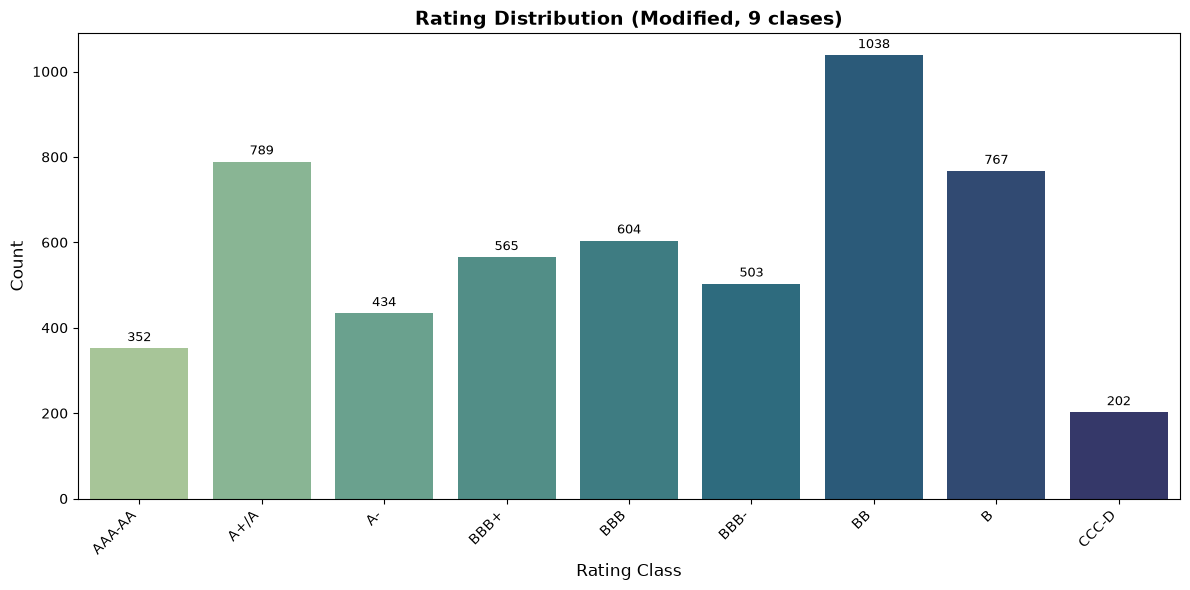

In [68]:
fig, ax = plt.subplots(figsize=(12, 6))
sns.countplot(data=df, x=target, order=X_ORDER, hue=target, hue_order=X_ORDER,
              palette="crest", legend=False, ax=ax)
ax.set_title(f"Rating Distribution (Modified, {len(X_ORDER)} clases)", fontsize=14, fontweight='bold')
ax.set_xlabel("Rating Class", fontsize=12)
ax.set_ylabel("Count", fontsize=12)
ax.set_xticks(range(len(X_ORDER)))
ax.set_xticklabels(X_LABELS, rotation=45, ha='right')
for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=9)
plt.tight_layout()
plt.savefig('rating_distribution_modified.png')
plt.show()

## Keras

In [69]:
from sklearn.metrics import f1_score

# ---------------------------------------------------------------
# Pesos por clase (modifican la función de pérdida, no son regularización)
# ---------------------------------------------------------------
def calcular_pesos(y, modo):
    """None -> sin pesos | 'suave' -> raíz de los pesos balanceados | 'balanceado' -> N / (K * n_c)."""
    if modo is None:
        return None
    clases = np.array(sorted(np.unique(y)))
    w = compute_class_weight('balanced', classes=clases, y=np.asarray(y))
    if modo == 'suave':
        w = np.sqrt(w)
    elif modo != 'balanceado':
        raise ValueError(f"Modo de pesos desconocido: {modo}")
    return {int(c): float(p) for c, p in zip(clases, w)}

def pesos_a_muestras(y, cw):
    """Convierte {clase: peso} en un peso por muestra (se usa en la validación)."""
    return np.array([cw[int(c)] for c in np.asarray(y)], dtype='float32')


def construir_modelo(cfg, n_entrada=None):
    """Construye un MLP a partir de un diccionario de configuración."""
    n_entrada  = n_entrada or input_dim
    capas      = cfg.get('capas', (32,))
    activacion = cfg.get('activacion', 'relu')
    batchnorm  = cfg.get('batchnorm', False)
    dropout    = cfg.get('dropout', 0.0)
    l1         = cfg.get('l1', 0.0)
    l2         = cfg.get('l2', 0.0)
    init       = 'he_normal' if activacion == 'relu' else 'glorot_uniform'
    reg = regularizers.L1L2(l1=l1, l2=l2) if (l1 or l2) else None

    m = models.Sequential([layers.Input(shape=(n_entrada,))])
    for n in capas:
        m.add(layers.Dense(n, kernel_initializer=init, kernel_regularizer=reg))
        if batchnorm:
            m.add(layers.BatchNormalization())
        m.add(layers.Activation(activacion))
        if dropout > 0:
            m.add(layers.Dropout(dropout))
    m.add(layers.Dense(num_classes))  # logits

    lr  = cfg.get('learning_rate', 1e-3)
    opt = cfg.get('optimizador', 'adam')
    if opt == 'sgd':
        optimizer = tf.keras.optimizers.SGD(learning_rate=lr)
    elif opt == 'momentum':
        optimizer = tf.keras.optimizers.SGD(learning_rate=lr, momentum=cfg.get('momentum', 0.9))
    elif opt == 'rmsprop':
        optimizer = tf.keras.optimizers.RMSprop(learning_rate=lr)
    else:
        optimizer = tf.keras.optimizers.Adam(learning_rate=lr)

    m.compile(
        optimizer=optimizer,
        loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=[
            tf.keras.metrics.SparseCategoricalCrossentropy(from_logits=True, name='ce'),
            tf.keras.metrics.SparseCategoricalAccuracy(name='acc'),
        ],
    )
    return m


def entrenar(cfg, epocas=10, paciencia=3, batch_size=256, semilla=SEED, verbose=0, datos=None):
    """Entrena con early stopping sobre la CE de dev. Devuelve (modelo, historial).
    cfg['pesos'] in {None, 'suave', 'balanceado'}. datos=(Xtr, ytr, Xdv, ydv) es opcional."""
    Xtr, ytr, Xdv, ydv = datos if datos is not None else (X_train_proc, y_train, X_dev_proc, y_dev)
    tf.keras.utils.set_random_seed(semilla)
    modelo = construir_modelo(cfg, n_entrada=Xtr.shape[1])

    cw = calcular_pesos(ytr, cfg.get('pesos'))
    # Si entrenamos con pesos, validamos con los mismos pesos (mismo objetivo en train y dev)
    val = (Xdv, ydv) if cw is None else (Xdv, ydv, pesos_a_muestras(ydv, cw))

    hist = modelo.fit(
        Xtr, ytr,
        validation_data=val,
        epochs=epocas, batch_size=batch_size, verbose=verbose,
        class_weight=cw,
        callbacks=[callbacks.EarlyStopping(monitor='val_ce', patience=paciencia,
                                           restore_best_weights=True)],
    )
    return modelo, hist


def evaluar_dev(modelo, Xdv=None, ydv=None):
    """Métricas en dev (nunca en test), sin pesos, con los mejores pesos restaurados."""
    Xdv = X_dev_proc if Xdv is None else Xdv
    ydv = np.asarray(y_dev if ydv is None else ydv)
    logits = modelo.predict(Xdv, verbose=0)
    pred = logits.argmax(axis=1)
    ce = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)(ydv, logits).numpy()
    return {
        'CE_dev':   round(float(ce), 4),
        'Acc_dev':  round(float((pred == ydv).mean()), 4),
        'F1_macro': round(float(f1_score(ydv, pred, average='macro', zero_division=0)), 4),
    }

In [70]:
# 1. Extracción dinámica de dimensiones
input_dim = X_train_proc.shape[1]
num_classes = len(X_ORDER)
print(f"input_dim = {input_dim} | num_classes = {num_classes}")

input_dim = 33 | num_classes = 9


In [71]:
# Misma arquitectura y optimizador para los 4 escaladores; 3 semillas para reducir ruido
CFG_ESCALADO = {'capas': (64, 32), 'activacion': 'relu', 'optimizador': 'adam', 'learning_rate': 1e-3}
ESCALADORES  = ['standard', 'robust', 'robust_clip', 'quantile']
SEMILLAS     = [SEED, SEED + 1, SEED + 2]

filas = []
for esc in ESCALADORES:
    prep = crear_preprocesador(esc)
    Xtr = prep.fit_transform(X_train)     # se ajusta solo con train
    Xdv = prep.transform(X_dev)
    mets = []
    for s in SEMILLAS:
        m, h = entrenar(CFG_ESCALADO, epocas=100, paciencia=10, semilla=s,
                        datos=(Xtr, y_train, Xdv, y_dev))
        mets.append(evaluar_dev(m, Xdv, y_dev))
    dfm = pd.DataFrame(mets)
    filas.append({
        'escalador': esc,
        'F1_macro': dfm['F1_macro'].mean(), 'F1_std': dfm['F1_macro'].std(),
        'Acc_dev':  dfm['Acc_dev'].mean(),  'CE_dev': dfm['CE_dev'].mean(),
    })

tabla_esc = pd.DataFrame(filas).sort_values('F1_macro', ascending=False).reset_index(drop=True)
display(tabla_esc.round(4))

# Se aplica el ganador a todo el resto del notebook
ESCALADOR = tabla_esc.loc[0, 'escalador']
print(f"\nEscalador elegido (por F1 macro en dev): {ESCALADOR}")
preprocesador = crear_preprocesador(ESCALADOR)
X_train_proc = preprocesador.fit_transform(X_train)
X_dev_proc   = preprocesador.transform(X_dev)
X_test_proc  = preprocesador.transform(X_test)
print(f"Dimensiones: {X_train_proc.shape} | {X_dev_proc.shape} | {X_test_proc.shape}")

,escalador,F1_macro,F1_std,Acc_dev,CE_dev
0,robust_clip,0.3268,0.0387,0.3791,1.7128
1,quantile,0.3145,0.0071,0.3670,1.6981
2,robust,0.1924,0.0982,0.2730,2.3419
3,standard,0.1691,0.0363,0.2984,2.1010



Escalador elegido (por F1 macro en dev): robust_clip
Dimensiones: (4203, 33) | (525, 33) | (526, 33)


### Modelo secuencial (red por mi)

In [72]:
# 2. Definición de la Arquitectura Secuencial (MLP)
tf.keras.utils.set_random_seed(SEED)
model = models.Sequential([
    # Capa de Entrada explícita
    layers.Input(shape=(input_dim,)),

    
    # Bloque Oculto 1: Extracción de representaciones de alto nivel
    #layers.Dense(128, kernel_regularizer=regularizers.l2(1e-4)),
    #layers.BatchNormalization(),
    #layers.Activation('relu'),
    #layers.Dropout(0.3),
    
    
    # Bloque Oculto 2: Compresión y abstracción de características
    layers.Dense(64, kernel_regularizer=regularizers.l2(1e-4)),
    layers.BatchNormalization(),
    layers.Activation('elu'),
    layers.Dropout(0.2),
    
    # Bloque Oculto 3: 
    layers.Dense(32, kernel_regularizer=regularizers.l2(1e-4)),
    layers.BatchNormalization(),
    layers.Activation('elu'),

    # Bloque Oculto 4: Mapeo denso hacia el espacio de clasificación
    layers.Dense(16, kernel_regularizer=regularizers.l2(1e-4)),
    layers.BatchNormalization(),
    layers.Activation('elu'),
    
    # Capa de Salida: num_classes logits lineales (sin Softmax explícito)
    layers.Dense(num_classes)
])

In [73]:
# 3. Compilación del Modelo
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['sparse_categorical_accuracy']
)
# Resumen de la arquitectura en consola
model.summary()

Model: "sequential_39"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_122 (Dense)               │ (None, 64)             │         2,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_83 (Activation)      │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_123 (Dense)               │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_84 (Activation)      │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_124 (Dense)               │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_85 (Activation)      │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_125 (Dense)               │ (None, 9)              │           153 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,385 (21.04 KB)

 Trainable params: 5,161 (20.16 KB)

 Non-trainable params: 224 (896.00 B)

In [74]:
# 4. Estrategia de Callbacks para Regularización Temporal
early_stopping = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=25,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-5,
    verbose=1
)

## Entrenamiento, curvas y métricas

In [75]:
# 5. Proceso de Entrenamiento y Validación
PESOS_MODO = 'balanceado'   # None | 'suave' | 'balanceado'

class_weight = calcular_pesos(y_train, PESOS_MODO)
if class_weight:
    print("class_weight:", {k: round(v, 2) for k, v in class_weight.items()})

# Con pesos, la validación también se pondera (mismo objetivo que en train)
datos_val = (X_dev_proc, y_dev) if class_weight is None \
            else (X_dev_proc, y_dev, pesos_a_muestras(y_dev, class_weight))

history = model.fit(
    X_train_proc, y_train,
    validation_data=datos_val,
    epochs=100,
    batch_size=256,
    class_weight=class_weight,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)
dev_loss, dev_accuracy = model.evaluate(X_dev_proc, y_dev, verbose=0)
print("\n[EVALUACIÓN EN DEV]")
print(f"Pérdida en Dev (sin pesos): {dev_loss:.4f}")
print(f"Exactitud en Dev: {dev_accuracy * 100:.2f}%")

class_weight: {0: 1.66, 1: 0.74, 2: 1.35, 3: 1.03, 4: 0.97, 5: 1.16, 6: 0.56, 7: 0.76, 8: 2.88}
Epoch 1/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 2.4516 - sparse_categorical_accuracy: 0.1463 - val_loss: 2.1857 - val_sparse_categorical_accuracy: 0.1790 - learning_rate: 0.0010
Epoch 2/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.1433 - sparse_categorical_accuracy: 0.1849 - val_loss: 2.0713 - val_sparse_categorical_accuracy: 0.1733 - learning_rate: 0.0010
Epoch 3/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2.0286 - sparse_categorical_accuracy: 0.1903 - val_loss: 2.0200 - val_sparse_categorical_accuracy: 0.1848 - learning_rate: 0.0010
Epoch 4/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.9895 - sparse_categorical_accuracy: 0.1934 - val_loss: 1.9850 - val_sparse_categorical_accuracy: 0.2019 - learning_rate: 0.0010
Epoch 5/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.9674 - sparse_categorical_accuracy: 0.1984 - val_loss: 1.9574 - val_sparse_categorical

              precision    recall  f1-score   support

      AAA-AA       0.40      0.66      0.49        35
        A+/A       0.47      0.29      0.36        79
          A-       0.25      0.34      0.29        44
        BBB+       0.38      0.55      0.45        56
         BBB       0.25      0.22      0.23        60
        BBB-       0.43      0.37      0.40        51
          BB       0.39      0.26      0.31       104
           B       0.43      0.42      0.42        76
       CCC-D       0.31      0.55      0.39        20

    accuracy                           0.37       525
   macro avg       0.37      0.41      0.37       525
weighted avg       0.38      0.37      0.36       525

Macro-F1: 0.3726
Exactitud ±1 clase (adyacente): 70.67%


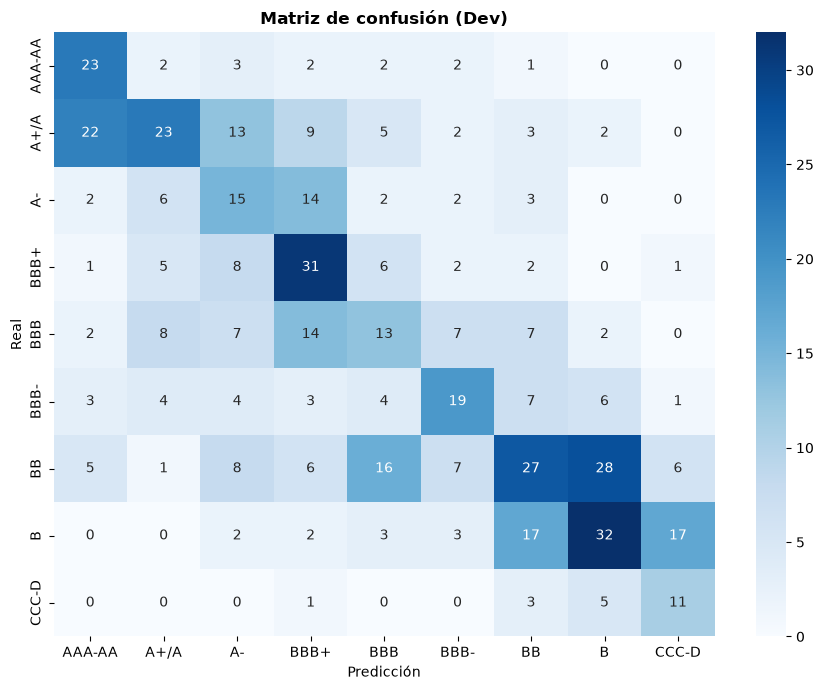

In [76]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score

y_pred = np.argmax(model.predict(X_dev_proc, verbose=0), axis=1)
y_true = y_dev.to_numpy()

print(classification_report(y_true, y_pred, labels=X_ORDER, target_names=X_LABELS, zero_division=0))
print(f"Macro-F1: {f1_score(y_true, y_pred, average='macro', labels=X_ORDER, zero_division=0):.4f}")
print(f"Exactitud ±1 clase (adyacente): {(np.abs(y_true - y_pred) <= 1).mean() * 100:.2f}%")

cm = confusion_matrix(y_true, y_pred, labels=X_ORDER)
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=X_LABELS, yticklabels=X_LABELS, ax=ax)
ax.set_xlabel("Predicción"); ax.set_ylabel("Real"); ax.set_title("Matriz de confusión (Dev)", fontweight='bold')
plt.tight_layout()
plt.show()

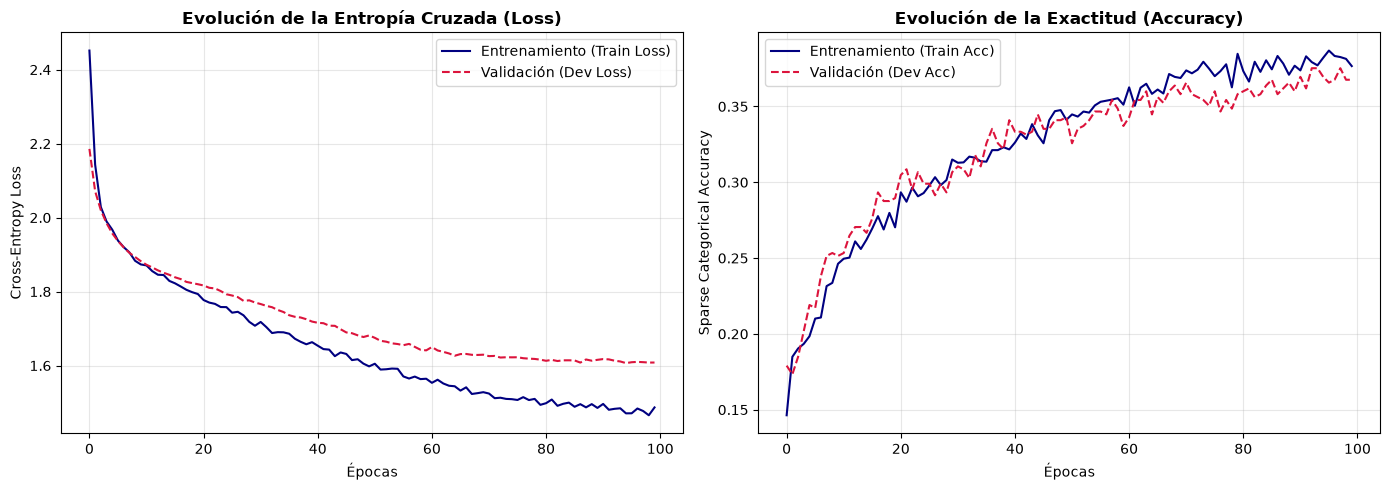

In [77]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Grafico de la Pérdida (Cross-Entropy)
ax1.plot(history.history['loss'], label='Entrenamiento (Train Loss)', color='navy')
ax1.plot(history.history['val_loss'], label='Validación (Dev Loss)', color='crimson', linestyle='--')
ax1.set_title("Evolución de la Entropía Cruzada (Loss)", fontweight='bold')
ax1.set_xlabel("Épocas")
ax1.set_ylabel("Cross-Entropy Loss")
ax1.legend()
ax1.grid(True, alpha=0.3)

# Gráfico de la Exactitud (Accuracy)
ax2.plot(history.history['sparse_categorical_accuracy'], label='Entrenamiento (Train Acc)', color='navy')
ax2.plot(history.history['val_sparse_categorical_accuracy'], label='Validación (Dev Acc)', color='crimson', linestyle='--')
ax2.set_title("Evolución de la Exactitud (Accuracy)", fontweight='bold')
ax2.set_xlabel("Épocas")
ax2.set_ylabel("Sparse Categorical Accuracy")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Comparación de optimizadores manualmente

,optimizador,CE_dev,Acc_dev,F1_macro,epocas
1,Momentum,1.7602,0.3810,0.3248,50
3,Adam,1.7606,0.3600,0.2752,50
2,RMSprop,1.8101,0.3371,0.2401,50
0,SGD,1.8636,0.3162,0.2169,50


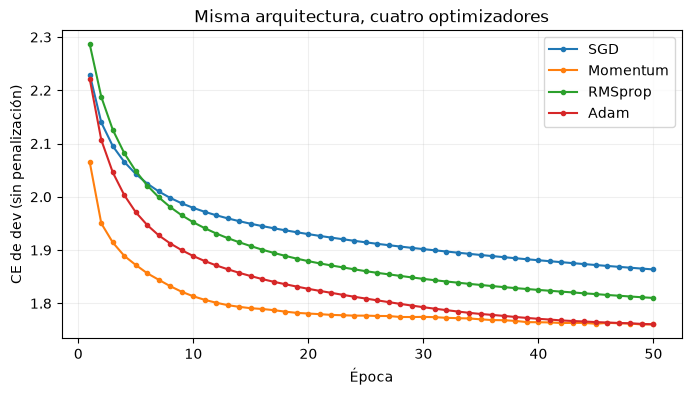

In [79]:
experimentos_opt = [
    ('SGD',      {'optimizador': 'sgd',      'learning_rate': 0.05}),
    ('Momentum', {'optimizador': 'momentum', 'learning_rate': 0.05, 'momentum': 0.9}),
    ('RMSprop',  {'optimizador': 'rmsprop',  'learning_rate': 0.001}),
    ('Adam',     {'optimizador': 'adam',     'learning_rate': 0.002}),
]

resultados_opt = []
historias_opt = {}

for nombre, params in experimentos_opt:
    modelo, hist = entrenar({'capas': (32,), **params}, epocas=50, paciencia=8)

    resultados_opt.append({
        'optimizador': nombre,
        **evaluar_dev(modelo),
        'epocas': len(hist.history['loss'])
    })
    historias_opt[nombre] = hist.history['val_ce']

display(pd.DataFrame(resultados_opt).sort_values('CE_dev'))

plt.figure(figsize=(8, 4))
for nombre, serie in historias_opt.items():
    plt.plot(range(1, len(serie) + 1), serie, marker='.', label=nombre)
plt.xlabel('Época')
plt.ylabel('CE de dev (sin penalización)')
plt.title('Misma arquitectura, cuatro optimizadores')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## Regularización y batch normalization

,tecnica,CE_train,CE_dev,Acc_dev,F1_macro,brecha,epocas
6,Pesos balanceados,1.5355,1.7834,0.3333,0.3301,0.2479,50
4,BatchNorm,1.3689,1.6519,0.3905,0.3281,0.2830,50
5,Pesos suaves (√),1.4635,1.7090,0.3448,0.3229,0.2455,50
1,L1,1.4429,1.6976,0.3886,0.3177,0.2547,50
2,L2,1.4486,1.6934,0.3790,0.3118,0.2448,50
0,Sin regularización,1.4410,1.6965,0.3829,0.3114,0.2555,50
3,Dropout 0.25,1.6824,1.7721,0.3429,0.2321,0.0897,50


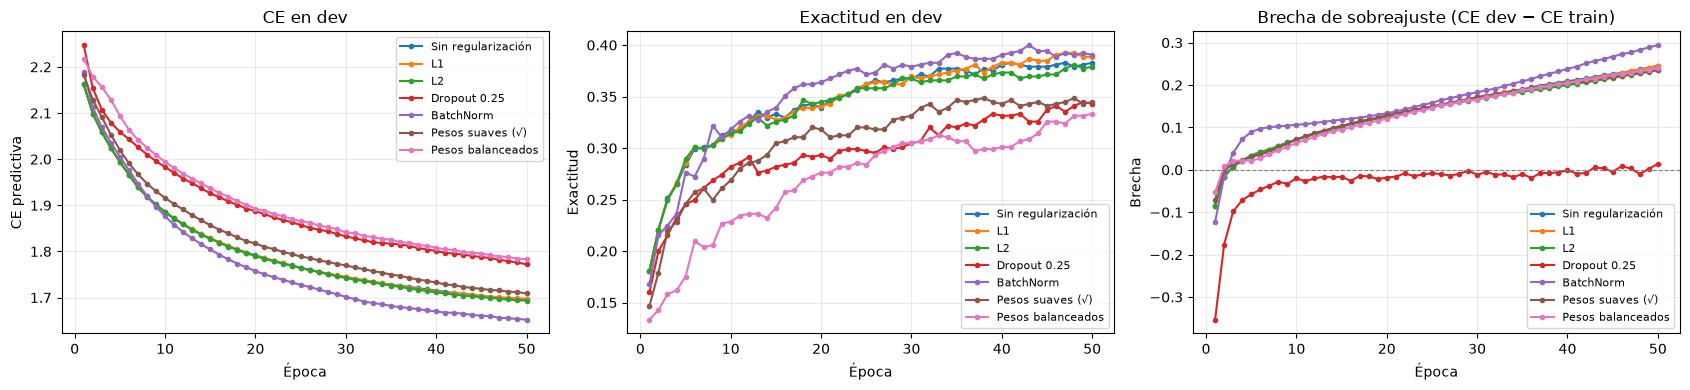

In [82]:
experimentos_reg = [
    ('Sin regularización', {}),
    ('L1',           {'l1': 1e-5}),
    ('L2',           {'l2': 1e-4}),
    ('Dropout 0.25', {'dropout': 0.25}),
    ('BatchNorm',    {'batchnorm': True}),
    ('Pesos suaves (√)',  {'pesos': 'suave'}),        # no es regularización: cambia la pérdida
    ('Pesos balanceados', {'pesos': 'balanceado'}),   # se compara en la misma tabla
]

resultados_reg = []
historias_reg = {}

for nombre, cambio in experimentos_reg:
    modelo, hist = entrenar({'capas': (64, 32), **cambio}, epocas=50, paciencia=8)

    # CE en train, medida sin dropout y sin penalización (comparable con dev)
    logits_tr = modelo.predict(X_train_proc, verbose=0)
    ce_train = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)(y_train, logits_tr).numpy()

    met = evaluar_dev(modelo)
    resultados_reg.append({
        'tecnica': nombre,
        'CE_train': round(float(ce_train), 4),
        **met,
        'brecha': round(met['CE_dev'] - float(ce_train), 4),   # dev - train
        'epocas': len(hist.history['loss'])
    })
    historias_reg[nombre] = hist.history

display(pd.DataFrame(resultados_reg).sort_values('F1_macro', ascending=False))

# --- Gráficas: CE dev, exactitud dev y brecha (val_ce - ce) ---
fig, ax = plt.subplots(1, 3, figsize=(17, 4))

for nombre, h in historias_reg.items():
    ep = range(1, len(h['val_ce']) + 1)
    ax[0].plot(ep, h['val_ce'], marker='.', label=nombre)
    ax[1].plot(ep, h['val_acc'], marker='.', label=nombre)
    brecha = np.array(h['val_ce']) - np.array(h['ce'])
    ax[2].plot(ep, brecha, marker='.', label=nombre)

ax[0].set(title='CE en dev', xlabel='Época', ylabel='CE predictiva')
ax[1].set(title='Exactitud en dev', xlabel='Época', ylabel='Exactitud')
ax[2].set(title='Brecha de sobreajuste (CE dev − CE train)', xlabel='Época', ylabel='Brecha')
ax[2].axhline(0, color='gray', lw=0.8, ls='--')

for a in ax:
    a.legend(fontsize=8)
    a.grid(alpha=0.25)

plt.tight_layout()
plt.show()

## Búsqueda aleatoria de hiperparámetros

Ensayo 1: {'l1': 0.0, 'capas': (64, 16), 'activacion': 'relu', 'optimizador': 'adam', 'learning_rate': 0.00048, 'batchnorm': False, 'pesos': None, 'dropout': 0.0, 'l2': 0.0001}
Ensayo 2: {'l1': 0.0, 'capas': (32,), 'activacion': 'elu', 'optimizador': 'momentum', 'learning_rate': 0.01172, 'batchnorm': True, 'pesos': 'balanceado', 'dropout': 0.0, 'l2': 1e-05}
Ensayo 3: {'l1': 0.0, 'capas': (64, 16, 16), 'activacion': 'relu', 'optimizador': 'adam', 'learning_rate': 0.00057, 'batchnorm': True, 'pesos': None, 'dropout': 0.0, 'l2': 0.0}
Ensayo 4: {'l1': 0.0, 'capas': (32, 16, 16), 'activacion': 'relu', 'optimizador': 'adam', 'learning_rate': 0.0036, 'batchnorm': False, 'pesos': 'balanceado', 'dropout': 0.1, 'l2': 0.0}
Ensayo 5: {'l1': 0.0, 'capas': (32,), 'activacion': 'elu', 'optimizador': 'adam', 'learning_rate': 0.0009, 'batchnorm': True, 'pesos': None, 'dropout': 0.1, 'l2': 0.0001}
Ensayo 6: {'l1': 0.0, 'capas': (16, 16), 'activacion': 'elu', 'optimizador': 'momentum', 'learning_rate': 0

,ensayo,capas,activacion,optimizador,lr,batchnorm,pesos,dropout,l2,CE_dev,Acc_dev,F1_macro,epocas
0,16,"(64, 64)",elu,adam,0.00170,True,suave,0.05,0.00001,1.5682,0.4457,0.4229,103
1,22,"(64,)",relu,momentum,0.04630,True,suave,0.05,0.00010,1.6711,0.4057,0.3910,113
2,21,"(32, 32)",elu,momentum,0.02854,True,suave,0.05,0.00000,1.6265,0.4057,0.3871,137
3,30,"(64, 32, 16)",relu,adam,0.00220,True,suave,0.05,0.00010,1.5869,0.3981,0.3846,83
4,29,"(64, 32, 16)",relu,momentum,0.03562,False,balanceado,0.10,0.00001,1.6445,0.3790,0.3824,143
5,13,"(64, 64, 32)",elu,momentum,0.04440,False,suave,0.10,0.00010,1.5578,0.3962,0.3814,125
6,31,"(64,)",relu,adam,0.00063,True,NaN,0.00,0.00010,1.6688,0.4152,0.3761,150
7,19,"(64, 64, 16)",elu,momentum,0.02225,True,balanceado,0.10,0.00001,1.6011,0.3771,0.3732,136
8,17,"(32, 32, 16)",elu,adam,0.00324,False,NaN,0.10,0.00000,1.5316,0.4324,0.3704,150
9,32,"(64,)",relu,adam,0.00288,False,NaN,0.00,0.00010,1.6866,0.4038,0.3667,85



Finalistas (media de 3 semillas):


,ensayo,F1_media,F1_std,Acc_media,CE_media
0,16,0.4042,0.0162,0.4241,1.5834
1,22,0.3719,0.0242,0.3905,1.6592
2,21,0.3620,0.0237,0.3866,1.6373



Mejor configuración (ensayo 16, por F1 macro medio en dev):
{'l1': 0.0, 'capas': (64, 64), 'activacion': 'elu', 'optimizador': 'adam', 'learning_rate': 0.0017, 'batchnorm': True, 'pesos': 'suave', 'dropout': 0.05, 'l2': 1e-05}


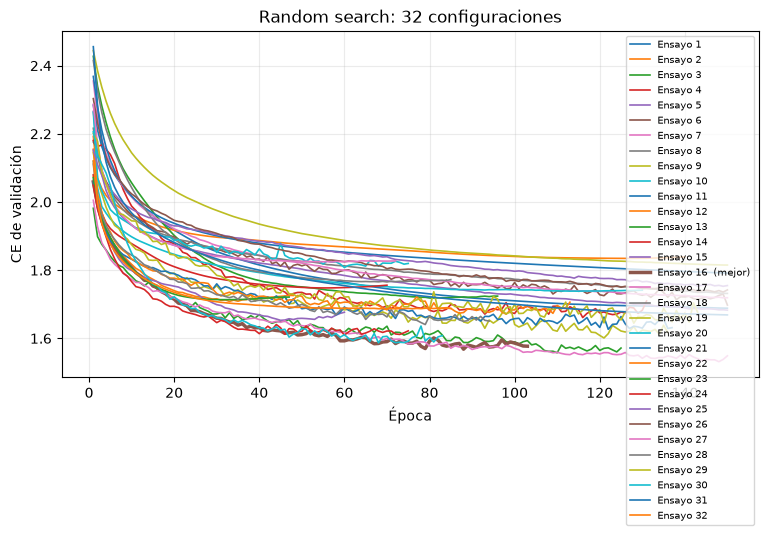

In [103]:
CRITERIO  = 'F1_macro'   # mayor es mejor
DESEMPATE = 'CE_dev'     # menor es mejor
FIJOS     = {'l1': 0.0}  # L1 no aportó en los experimentos de regularización

N_ENSAYOS = 32
EPOCAS    = 150
PACIENCIA = 15

ESPACIO = {
    'n_capas':     [1, 2, 3],
    'neuronas':    [16, 32, 64],                  # se sortea por capa y luego se ordena de mayor a menor
    'activacion':  ['relu', 'elu'],               # 'tanh' fuera; añádelo si quieres probarlo
    'optimizador': ['momentum', 'rmsprop', 'adam'],   # SGD plano fuera (converge muy lento)
    'batchnorm':   [True, False],
    'pesos':       [None, 'suave', 'balanceado'],
    'dropout':     [0.0, 0.05, 0.1],
    'l2':          [0.0, 1e-5, 1e-4],
}
# Muestreo log-uniforme del learning rate, con rangos acotados por optimizador
RANGO_LR = {
    'momentum': (5e-3, 5e-2),
    'rmsprop':  (3e-4, 5e-3),
    'adam':     (3e-4, 5e-3),
}

def sortear_cfg(rng):
    n_capas = rng.choice(ESPACIO['n_capas'])
    opt = rng.choice(ESPACIO['optimizador'])
    lo, hi = RANGO_LR[opt]
    lr = float(np.exp(rng.uniform(np.log(lo), np.log(hi))))
    neuronas = sorted((rng.choice(ESPACIO['neuronas']) for _ in range(n_capas)), reverse=True)  # embudo
    return {
        **FIJOS,
        'capas':         tuple(neuronas),
        'activacion':    rng.choice(ESPACIO['activacion']),
        'optimizador':   opt,
        'learning_rate': round(lr, 5),
        'batchnorm':     rng.choice(ESPACIO['batchnorm']),
        'pesos':         rng.choice(ESPACIO['pesos']),
        'dropout':       rng.choice(ESPACIO['dropout']),   # antes no se sorteaba
        'l2':            rng.choice(ESPACIO['l2']),        # antes no se sorteaba
    }

# ---------------- Etapa 1: random search (1 semilla por ensayo) ----------------
rng = random.Random(SEED)   # misma semilla -> mismos sorteos
resultados_rs, historias_rs, configs_rs = [], {}, {}

for i in range(1, N_ENSAYOS + 1):
    cfg = sortear_cfg(rng)
    print(f"Ensayo {i}: {cfg}")
    modelo, hist = entrenar(cfg, epocas=EPOCAS, paciencia=PACIENCIA)

    resultados_rs.append({
        'ensayo':      i,
        'capas':       cfg['capas'],
        'activacion':  cfg['activacion'],
        'optimizador': cfg['optimizador'],
        'lr':          cfg['learning_rate'],
        'batchnorm':   cfg['batchnorm'],
        'pesos':       cfg['pesos'],
        'dropout':     cfg['dropout'],
        'l2':          cfg['l2'],
        **evaluar_dev(modelo),
        'epocas':      len(hist.history['loss']),
    })
    historias_rs[i] = hist.history['val_ce']
    configs_rs[i] = cfg

tabla_rs = (pd.DataFrame(resultados_rs)
              .sort_values([CRITERIO, DESEMPATE], ascending=[False, True])
              .reset_index(drop=True))
display(tabla_rs)

# ---------------- Etapa 2: los TOP_K finalistas, repetidos con varias semillas ----------------
TOP_K = 3
SEMILLAS_REFINO = [SEED, SEED + 1, SEED + 2]
finalistas = tabla_rs.head(TOP_K)['ensayo'].astype(int).tolist()

filas_ref = []
for i in finalistas:
    mets = []
    for s in SEMILLAS_REFINO:
        m, h = entrenar(configs_rs[i], epocas=EPOCAS, paciencia=PACIENCIA, semilla=s)
        mets.append(evaluar_dev(m))
    d = pd.DataFrame(mets)
    filas_ref.append({
        'ensayo':    i,
        'F1_media':  d['F1_macro'].mean(), 'F1_std': d['F1_macro'].std(),
        'Acc_media': d['Acc_dev'].mean(),  'CE_media': d['CE_dev'].mean(),
    })

tabla_ref = pd.DataFrame(filas_ref).sort_values('F1_media', ascending=False).reset_index(drop=True)
print("\nFinalistas (media de 3 semillas):")
display(tabla_ref.round(4))

mejor_ensayo = int(tabla_ref.loc[0, 'ensayo'])
mejor_cfg = configs_rs[mejor_ensayo]
print(f"\nMejor configuración (ensayo {mejor_ensayo}, por F1 macro medio en dev):\n{mejor_cfg}")

# Curvas de CE en dev por ensayo (con pesos, la CE de validación está ponderada)
plt.figure(figsize=(9, 4.5))
for i, serie in historias_rs.items():
    etiqueta = f"Ensayo {i}" + ("  (mejor)" if i == mejor_ensayo else "")
    plt.plot(range(1, len(serie) + 1), serie,
             lw=2.5 if i == mejor_ensayo else 1.2, label=etiqueta)
plt.xlabel('Época')
plt.ylabel('CE de validación')
plt.title(f'Random search: {N_ENSAYOS} configuraciones')
plt.legend(fontsize=7)
plt.grid(alpha=0.25)
plt.show()

## Evaluación final en Test y conclusiones

Epoch 1/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - acc: 0.1832 - ce: 2.2370 - loss: 2.1751 - val_acc: 0.2286 - val_ce: 2.0590 - val_loss: 2.0060
Epoch 2/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - acc: 0.2681 - ce: 1.9704 - loss: 1.9293 - val_acc: 0.2667 - val_ce: 1.9935 - val_loss: 1.9496
Epoch 3/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - acc: 0.2948 - ce: 1.8959 - loss: 1.8625 - val_acc: 0.2857 - val_ce: 1.9453 - val_loss: 1.9062
Epoch 4/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - acc: 0.3072 - ce: 1.8525 - loss: 1.8224 - val_acc: 0.3105 - val_ce: 1.9127 - val_loss: 1.8756
Epoch 5/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - acc: 0.3119 - ce: 1.8207 - loss: 1.7930 - val_acc: 0.3067 - val_ce: 1.8888 - val_loss: 1.8547
Epoch 6/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - acc: 0.3305 - ce: 1.8013 - loss: 1.7743 - val_acc: 0.3181 - val_ce: 1.8662 - val_loss: 1.8341
Epoch 7/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - acc: 0.3338 - ce: 1.7803 - loss: 1.7554 - val_acc: 0.3219 - val_

Model: "sequential_364"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1146 (Dense)              │ (None, 64)             │         2,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_446         │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_782 (Activation)     │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_311 (Dropout)           │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1147 (Dense)              │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_447         │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_783 (Activation)     │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_312 (Dropout)           │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1148 (Dense)              │ (None, 9)              │           585 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,789 (85.12 KB)

 Trainable params: 7,177 (28.04 KB)

 Non-trainable params: 256 (1.00 KB)

 Optimizer params: 14,356 (56.08 KB)

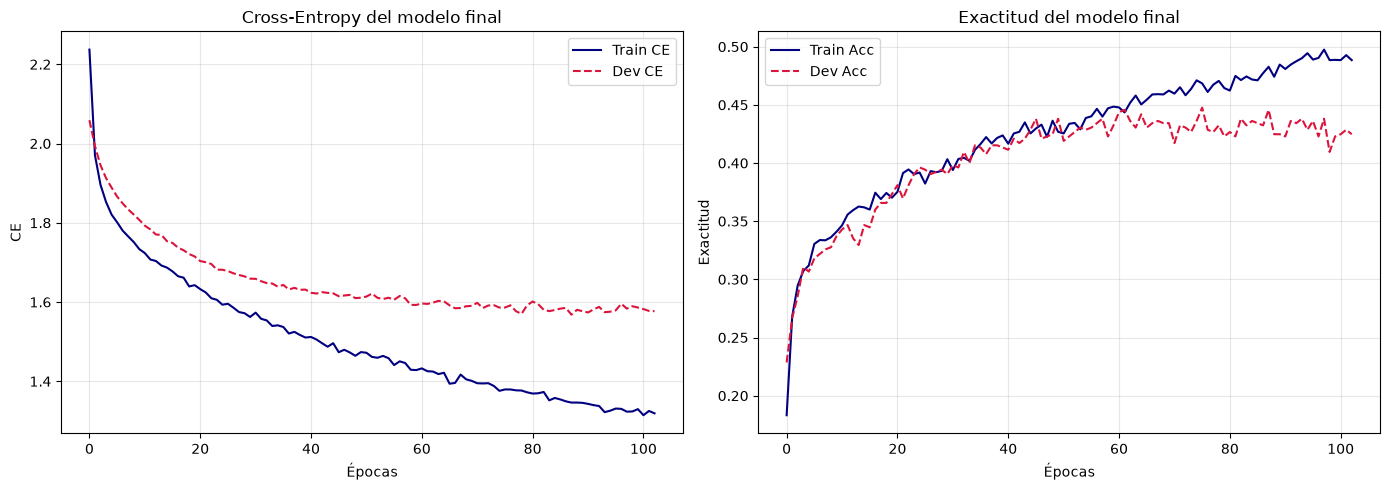

CE en test:        1.6001
Exactitud en test: 38.40%
Macro-F1 en test:  0.3817
Exactitud ±1 clase (adyacente): 68.44%

              precision    recall  f1-score   support

      AAA-AA       0.46      0.54      0.50        35
        A+/A       0.33      0.42      0.37        79
          A-       0.24      0.21      0.23        43
        BBB+       0.23      0.23      0.23        57
         BBB       0.30      0.31      0.31        61
        BBB-       0.31      0.22      0.26        50
          BB       0.48      0.44      0.46       104
           B       0.55      0.52      0.53        77
       CCC-D       0.52      0.60      0.56        20

    accuracy                           0.38       526
   macro avg       0.38      0.39      0.38       526
weighted avg       0.38      0.38      0.38       526



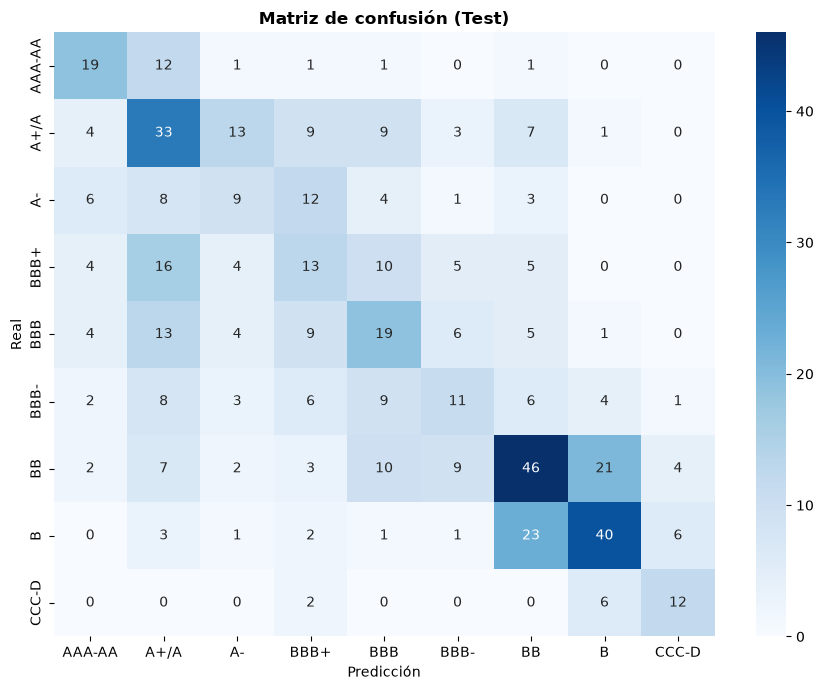

In [104]:
modelo_final, hist_final = entrenar(mejor_cfg, epocas=EPOCAS, paciencia=PACIENCIA, verbose=1)
modelo_final.summary()
 
# %% Curvas del modelo final
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(hist_final.history['ce'], label='Train CE', color='navy')
ax1.plot(hist_final.history['val_ce'], label='Dev CE', color='crimson', linestyle='--')
ax1.set(title='Cross-Entropy del modelo final', xlabel='Épocas', ylabel='CE')
ax2.plot(hist_final.history['acc'], label='Train Acc', color='navy')
ax2.plot(hist_final.history['val_acc'], label='Dev Acc', color='crimson', linestyle='--')
ax2.set(title='Exactitud del modelo final', xlabel='Épocas', ylabel='Exactitud')
for a in (ax1, ax2):
    a.legend()
    a.grid(alpha=0.3)
plt.tight_layout()
plt.show()
 
# %% Evaluación ÚNICA en test
from sklearn.metrics import classification_report, confusion_matrix, f1_score
 
logits_test = modelo_final.predict(X_test_proc, verbose=0)
y_pred = logits_test.argmax(axis=1)
y_true = y_test.to_numpy()
 
ce_test = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)(y_true, logits_test).numpy()
print(f"CE en test:        {ce_test:.4f}")
print(f"Exactitud en test: {(y_pred == y_true).mean() * 100:.2f}%")
print(f"Macro-F1 en test:  {f1_score(y_true, y_pred, average='macro', labels=X_ORDER, zero_division=0):.4f}")
print(f"Exactitud ±1 clase (adyacente): {(np.abs(y_true - y_pred) <= 1).mean() * 100:.2f}%\n")
 
print(classification_report(y_true, y_pred, labels=X_ORDER,
                            target_names=X_LABELS, zero_division=0))
 
cm = confusion_matrix(y_true, y_pred, labels=X_ORDER)
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=X_LABELS, yticklabels=X_LABELS, ax=ax)
ax.set_xlabel("Predicción")
ax.set_ylabel("Real")
ax.set_title("Matriz de confusión (Test)", fontweight='bold')
plt.tight_layout()
plt.show()

In [105]:
# Baselines con la misma preparación de datos y los mismos pesos que el MLP final.
# Ninguno se ajusta con test: solo se evalúan una vez.
def softmax(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

def metricas_completas(y_true, y_pred, proba):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return {
        'Accuracy': (y_pred == y_true).mean(),
        'Macro-F1': f1_score(y_true, y_pred, average='macro', labels=X_ORDER, zero_division=0),
        '±1 clase': (np.abs(y_true - y_pred) <= 1).mean(),
        'CE':       log_loss(y_true, proba, labels=X_ORDER),
    }

cw_base = calcular_pesos(y_train, mejor_cfg.get('pesos'))
baselines = {
    'Clase mayoritaria':     DummyClassifier(strategy='prior'),
    'Random Forest':         RandomForestClassifier(n_estimators=300, class_weight=cw_base,
                                                    random_state=SEED, n_jobs=-1),
    'HistGradientBoosting':  HistGradientBoostingClassifier(class_weight=cw_base, random_state=SEED),
}

filas = []
for nombre, clf in baselines.items():
    clf.fit(X_train_proc, y_train)
    proba = clf.predict_proba(X_test_proc)
    pred = clf.classes_[proba.argmax(axis=1)]
    filas.append({'Modelo': nombre, **metricas_completas(y_test, pred, proba)})

# MLP final (logits_test viene de la celda de evaluación en test)
proba_mlp = softmax(logits_test)
pred_mlp = np.asarray(X_ORDER)[proba_mlp.argmax(axis=1)]
filas.append({'Modelo': 'MLP final (este notebook)', **metricas_completas(y_test, pred_mlp, proba_mlp)})

tabla_final = pd.DataFrame(filas).set_index('Modelo')
display(tabla_final.round(4))

# Se guarda para la celda "Resumen ejecutivo" del inicio
resumen = {
    'tabla': tabla_final.round(4).reset_index().to_dict('records'),
    'config_mlp': mejor_cfg,
    'escalador': ESCALADOR,
    'semilla': SEED,
}
with open('resumen_ejecutivo.json', 'w', encoding='utf-8') as f:
    json.dump(resumen, f, indent=2, ensure_ascii=False,
              default=lambda o: o.item() if hasattr(o, 'item') else str(o))
print("Resumen guardado en resumen_ejecutivo.json")

,Accuracy,Macro-F1,±1 clase,CE
Modelo,,,,
Clase mayoritaria,0.1977,0.0367,0.4392,2.1102
Random Forest,0.4259,0.3979,0.8118,1.8432
HistGradientBoosting,0.4202,0.3927,0.7966,1.7789
MLP final (este notebook),0.3840,0.3817,0.6844,1.6001


Resumen guardado en resumen_ejecutivo.json


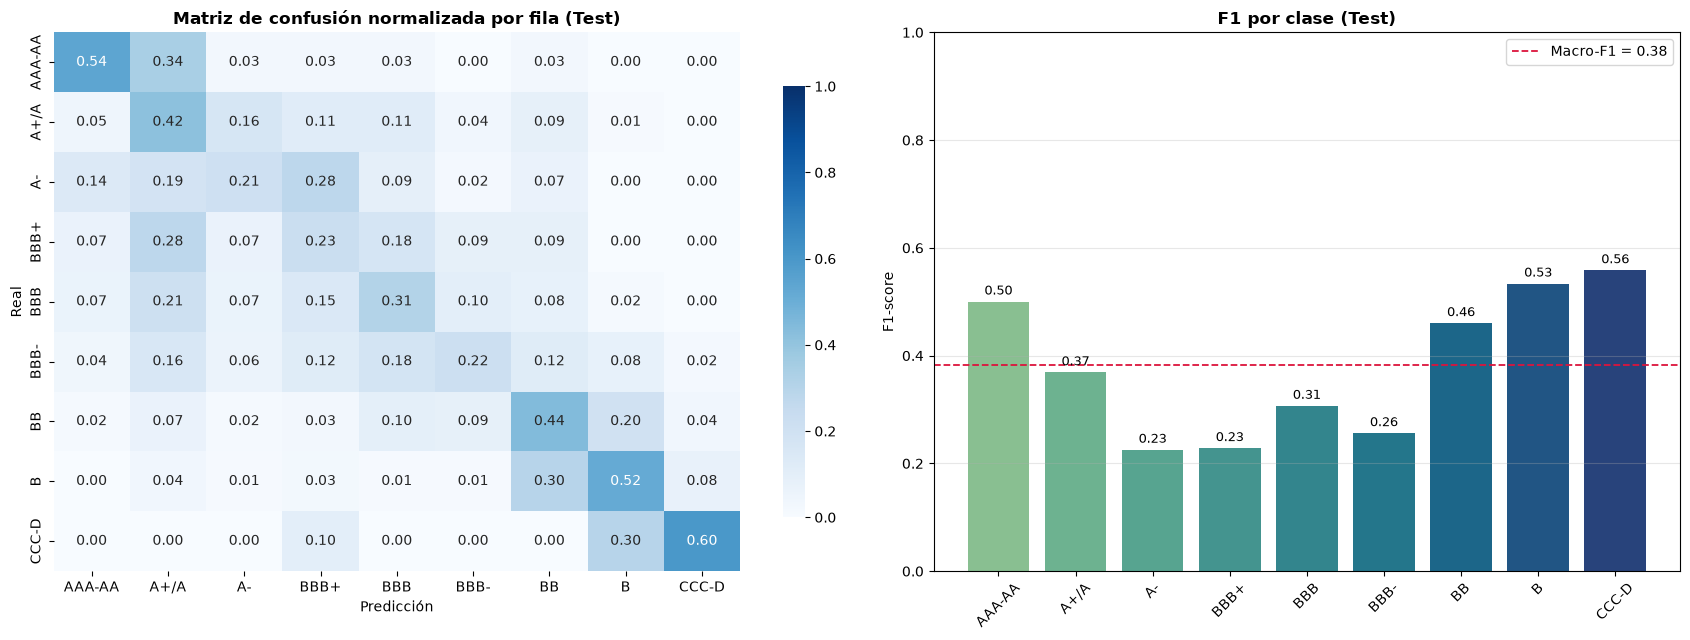

In [106]:
cm_norm = confusion_matrix(y_true, y_pred, labels=X_ORDER, normalize='true')   # cada fila suma 1
f1_clase = f1_score(y_true, y_pred, average=None, labels=X_ORDER, zero_division=0)
f1_macro = f1_clase.mean()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={'width_ratios': [1.15, 1]})

# Izquierda: matriz de confusión normalizada por fila (= recall de cada clase en la diagonal)
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1,
            xticklabels=X_LABELS, yticklabels=X_LABELS, ax=ax1, cbar_kws={'shrink': 0.8})
ax1.set_xlabel("Predicción")
ax1.set_ylabel("Real")
ax1.set_title("Matriz de confusión normalizada por fila (Test)", fontweight='bold')

# Derecha: F1 por clase
barras = ax2.bar(X_LABELS, f1_clase, color=sns.color_palette('crest', len(X_ORDER)))
ax2.bar_label(barras, fmt='%.2f', padding=3, fontsize=9)
ax2.axhline(f1_macro, color='crimson', ls='--', lw=1.3, label=f'Macro-F1 = {f1_macro:.2f}')
ax2.set_ylim(0, 1)
ax2.set_ylabel("F1-score")
ax2.set_title("F1 por clase (Test)", fontweight='bold')
ax2.tick_params(axis='x', rotation=45)
ax2.grid(axis='y', alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()

## Mención Honorifica

Para después se planea implementar métodos como lo son 
- Regresión ordinal
- Etiquetas suavizadas hacia las clases vecinas.
- Una pérdida que penalice la distancia entre clases.